# Componente 3 — Una segunda mirada: comparación de enfoques y casos raros

**Ventana:** 1 de enero a 31 de agosto de 2026. **Universo:** los 58,275 viajes de `tc.cargar_universo()`, el mismo de los Componentes 1 y 2. Se compara la misma demanda observada; no son pronósticos ni ahorros garantizados. Las capacidades legales dependen de taras provisionales y el peso no informa volumen ni dimensiones. Las alternativas son escenarios independientes: no se suman.

**Alineación con C1 y C2.** Las tarifas de referencia, capacidades y reglas son las mismas de esos componentes, así que los enfoques reproducen sus cifras: el right-sizing por reglas de C1 (38.5 M) y el MILP con flota de C2 (31.6 M). Además se incorporan dos conclusiones de C2: qué movimientos tienen **respaldo causal** (solo 3 ejes → 2 ejes y Big Coil → 2 ejes) y que el ahorro depende de la **disponibilidad** de la unidad sugerida. La incertidumbre se calcula como en C1 (sección 6.2).

In [1]:
# Rutas: el notebook vive en analisis_estadistico_IA/, pero data/, config/ y resultados_ternium/ están en la raíz.
# Se trabaja desde la raíz y se agregan las carpetas de código al path para importar sus módulos.
import os, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'analisis_estadistico_IA' else Path.cwd()
os.chdir(RAIZ)
for _carpeta in ('analisis_estadistico_IA', 'data_processing'):
    if str(RAIZ / _carpeta) not in sys.path:
        sys.path.insert(0, str(RAIZ / _carpeta))

# Propósito: Cargar el universo común (58,275 viajes) y preparar el optimizador del Componente 2 (tarifas de
# referencia ruta × unidad, capacidades y disponibilidad de flota).
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
import ternium_comun as tc
import componente_3_optimizacion as opt
tc.aplicar_estilo()
df = tc.cargar_universo().reset_index(drop=True)
df['Programado_t'] = df['Programado_kg'] / 1000
assert len(df) == 58275
opt.preparar_optimizador(df)
T = opt.tarifas()                                    # tarifa de referencia: mediana ruta × unidad (≥ 5 viajes)
# k0 = unidad actual de cada viaje; rr = índice de su ruta; cap = carga útil legal por unidad
k0 = opt.o.k0.to_numpy(); rr = opt.o.r.to_numpy()
cap = opt.CAP_LEG
q = df.Programado_t.to_numpy(); qr = df.Toneladas_Reales.to_numpy()      # peso programado y peso real (t)
costo = df.Costo.to_numpy(dtype=float)
N, UNI = len(df), np.array(tc.UNIDADES)
print(f"Universo: {N:,} viajes; {df.FECHA_EGRESO.min():%Y-%m-%d} a {df.FECHA_EGRESO.max():%Y-%m-%d}")

Universo: 58,275 viajes; 2026-01-01 a 2026-08-31


## 1. Cinco perspectivas en igualdad de condiciones

| Enfoque | Qué decide | Peso que usa | Disponibilidad de flota |
|---|---|---|---|
| **Actual** | Lo que ocurrió | – | – |
| **Reglas (C1)** | Para cada viaje, la unidad factible más barata de su ruta; se mueve si ahorra ≥ 3 % (C1, sección 6.1) | Real | No |
| **Heurística** | La unidad más frecuente de la ruta y, si no es elegible, la más pequeña compatible; mismas reglas de tarifa, peso y materialidad | Programado | No |
| **MILP con flota (C2)** | Asignación de menor costo con disponibilidad semanal por planta (C2, sección 6) | Programado | Sí |
| **Consolidación FFD** | Juntar cargas de 3 ejes del mismo día y ruta en un solo camión | Programado | – |

En los tres enfoques de asignación, el ahorro de un viaje es la tarifa de referencia de su unidad actual menos la de la unidad asignada, en la misma ruta (como en C1 y C2). La heurística y las reglas de C1 no imponen disponibilidad, así que su factibilidad de flota no está garantizada.

**Respaldo causal.** C2 (secciones 3–4) solo sostiene el efecto de dos movimientos: **3 ejes → 2 ejes** (−21 %) y **Big Coil → 2 ejes** (−29 %), robustos a confusores, a la replicación temporal y al placebo. Los demás (Torton → 2 ejes, 2 ejes → 3 ejes, Big Coil → 3 ejes, 3 ejes → Full) no se distinguen del ruido o de un efecto del transportista. Por eso cada ahorro se separa en **con respaldo causal** y **sin respaldo**.

**Consolidación:** First-Fit Decreasing sobre peso programado, por día, planta y destino, para viajes existentes de **3 ejes en la misma ruta**; cada carga es indivisible y la suma no puede exceder 36.575 t. Se conserva el viaje más pesado de cada grupo y su costo observado; los demás se eliminan. La carga real se suma para las métricas físicas. Se asume misma tarifa, producto compatible, horarios compatibles y capacidad suficiente al consolidar: son supuestos por verificar. No se aplica right-sizing simultáneo. El dato es viaje, no pedido: se asume que cada viaje puede tratarse como carga indivisible.

In [2]:
# Propósito: Calcular la unidad asignada por cada enfoque (reglas de C1, heurística y MILP de C2), su ahorro por viaje
# y si el movimiento tiene respaldo causal según C2. Se verifica que se reproducen las cifras de C1 y C2.
# Las reglas de C1, el ahorro por viaje y el respaldo causal viven en componente_3_optimizacion.py (compartido con C4).
ahorro, con_respaldo = opt.ahorro, opt.con_respaldo

# Regla del Componente 1 (sección 6.1): con el peso real y sin límite de flota
k_c1 = opt.decidir_c1(T, qr)

# Heurística: entre las unidades factibles (mismas reglas que el MILP), la más frecuente en la ruta;
# si esa no es factible, la de menor capacidad
C, tarifa0 = opt.factibles(T)
freq = pd.crosstab(opt.o['r'], opt.o['k0']).reindex(index=range(len(opt.rutas_o)), columns=range(opt.K), fill_value=0).to_numpy()
k_h = k0.copy()
for i in range(N):
    candidatos = np.flatnonzero(np.isfinite(C[i]))
    candidatos = candidatos[candidatos != k0[i]]
    if len(candidatos):
        mas = int(np.argmax(freq[rr[i]]))
        k_h[i] = mas if mas in candidatos else candidatos[np.argmin(opt.CAP_LEG[candidatos])]

# MILP del Componente 2 (con disponibilidad semanal de flota) y su versión sin flota (para descomponer diferencias)
k_m, _ = opt.resolver(T, con_flota=True)
k_libre, _ = opt.resolver(T, con_flota=False)

ASIGNACION = {'Reglas (C1)': k_c1, 'Heurística': k_h, 'MILP con flota (C2)': k_m}
for nombre, k in ASIGNACION.items():
    a, r = ahorro(k), con_respaldo(k)
    print(f'{nombre:20s}: {(k != k0).sum():5,} viajes cambian; ahorro {a.sum()/1e6:5.1f} M MXN '
          f'(con respaldo causal {a[r].sum()/1e6:4.1f} M en {r.sum():,} viajes)')
# Consistencia con los componentes anteriores
assert (k_c1 != k0).sum() == 5784 and abs(ahorro(k_c1).sum() / 1e6 - 38.49) < 0.01      # C1, sección 6
assert (k_m != k0).sum() == 4721 and abs(ahorro(k_m).sum() / 1e6 - 31.60) < 0.01        # C2, sección 6

Reglas (C1)         : 5,784 viajes cambian; ahorro  38.5 M MXN (con respaldo causal 34.9 M en 4,867 viajes)
Heurística          : 5,377 viajes cambian; ahorro  31.2 M MXN (con respaldo causal 26.1 M en 3,600 viajes)
MILP con flota (C2) : 4,721 viajes cambian; ahorro  31.6 M MXN (con respaldo causal 27.4 M en 3,526 viajes)


In [3]:
# Propósito: Consolidación First-Fit Decreasing. Los grupos excluyen rutas ambiguas y cargas programadas inválidas.
activo = np.ones(N, dtype=bool); carga_c = qr.copy(); interv_c = np.zeros(N, dtype=bool)
elegible = ((df.Unidad.astype(str) == '3 Ejes') & df.Ruta_ID.notna() & df['Ciudad Destino'].notna()
            & (df.Programado_t > 0) & (df.Programado_t <= 36.575) & (df.Toneladas_Reales > 0))
g = df.loc[elegible].groupby([df.FECHA_EGRESO.dt.normalize(), tc.PLANTA, 'Ciudad Destino', 'Ruta_ID'], observed=True, dropna=True)
# Dentro de cada grupo, las cargas (de mayor a menor) entran al primer camión donde caben
for _, grupo in g:
    bins = []
    for i in grupo.index[np.argsort(-q[grupo.index], kind='stable')]:
        for b in bins:
            if b[0] + q[i] <= 36.575 + 1e-9:
                b[0] += q[i]; b[1].append(i); break
        else:
            bins.append([q[i], [i]])
    # Camiones con más de una carga: se conserva el más pesado y los demás viajes se eliminan
    for _, ids in bins:
        if len(ids) > 1:
            lider, resto = ids[0], ids[1:]
            activo[resto] = False; carga_c[lider] = qr[ids].sum(); carga_c[resto] = 0
            interv_c[ids] = True
# Ahorro = costo observado de los viajes eliminados
ah_c = np.where(~activo, costo, 0)
print(f'Consolidación: {interv_c.sum():,} viajes involucrados; {(~activo).sum():,} viajes eliminados.')

Consolidación: 74 viajes involucrados; 37 viajes eliminados.


### Comparación e incertidumbre

**Mismo método que el Componente 1 (sección 6.2).** Bootstrap de dos vías **transportista × ruta**, B = 1,000, con el mismo generador y semilla. La decisión de cada enfoque se toma una sola vez, con las tarifas observadas; en cada réplica se **recalculan las tarifas de referencia** con los pesos remuestreados y se evalúan los **mismos movimientos**. Así el intervalo incluye la incertidumbre de la tarifa de referencia, no solo la de la mezcla de viajes. El ahorro con IC es (proporción del gasto ahorrada, con su IC) × gasto observado, como en C1. Con este método, el enfoque de reglas reproduce exactamente el IC de C1.

**Consolidación:** su ahorro es el costo observado de los viajes eliminados (no depende de tarifas de referencia), así que su IC solo refleja la mezcla de viajes; el grupo empacado se trata como fijo.

**Métricas físicas.** Capacidad ociosa suma `max(capacidad legal − carga real, 0)` por viaje resultante (total normalizado a 58,275 viajes en cada réplica). Costo/ton es gasto total entre toneladas transportadas. Utilización y costo por t-km son medianas por viaje resultante (este último solo con km confiable y con tarifas observadas); sus IC usan los mismos pesos de dos vías. En los enfoques de asignación, "viajes intervenidos" son cambios de unidad; en consolidación, viajes originales involucrados.

In [4]:
# Propósito: Comparar los cinco enfoques con IC 95 % por bootstrap de dos vías transportista × ruta, con el método de C1:
# mismos movimientos, tarifas de referencia recalculadas en cada réplica.
B, BLOQUE = 1000, 100
km = df.Kilometros_Ruta.to_numpy(); confiable = df.Km_Confiable.fillna(False).astype(bool).to_numpy()
GASTO = costo.sum()

def fisicas(k, ahorro_obs, activos=None, carga=None):
    # Métricas por viaje de un enfoque: capacidad ociosa, utilización y costo por t-km (con tarifas observadas)
    activos = np.ones(N, bool) if activos is None else activos
    carga = qr if carga is None else carga
    capacidad = cap[k]
    util = np.divide(carga, capacidad, out=np.full(N, np.nan), where=activos & (capacidad > 0))
    tkm = np.divide(costo - ahorro_obs, carga * km, out=np.full(N, np.nan), where=activos & confiable & (carga > 0) & (km > 0))
    ociosa = np.where(activos, np.maximum(capacidad - carga, 0), 0)
    return util, tkm, ociosa

ENFOQUES = ['Actual', *ASIGNACION, 'Consolidación FFD']
K_ENF = {'Actual': k0, **ASIGNACION, 'Consolidación FFD': k0}
AH_OBS = {e: (np.zeros(N) if e == 'Actual' else ah_c if e == 'Consolidación FFD' else ahorro(K_ENF[e])) for e in ENFOQUES}
RESP = {e: (con_respaldo(K_ENF[e]) if e in ASIGNACION else np.zeros(N, bool)) for e in ENFOQUES}
FIS = {e: (fisicas(k0, ah_c, activo, carga_c) if e == 'Consolidación FFD' else fisicas(K_ENF[e], AH_OBS[e])) for e in ENFOQUES}

# Orden de cada métrica de mediana (se ordena una vez y se reusa en todas las réplicas)
def ordenar(x):
    # Índices de los valores válidos de x, de menor a mayor
    ids = np.flatnonzero(np.isfinite(x))
    return ids[np.argsort(x[ids], kind='stable')], x
ORDEN = {(e, m): ordenar(FIS[e][j]) for e in ENFOQUES for j, m in enumerate(['util', 'tkm'])}
def mediana_pond(e, m, w):
    # Mediana ponderada por los pesos de la réplica
    ids, x = ORDEN[(e, m)]
    acum = np.cumsum(w[ids])
    return x[ids[np.searchsorted(acum, acum[-1] / 2, side='left')]]

# Réplicas: mismos pesos para todos los enfoques (comparación pareada) y mismo generador que C1
rng = np.random.default_rng(2026)
rep = {e: {k: [] for k in ['pct', 'pct_resp', 'ociosa', 'costo_ton', 'util', 'tkm']} for e in ENFOQUES}
for _ in range(0, B, BLOQUE):
    for w in opt.pesos_dos_vias(rng, BLOQUE):                      # transportistas y rutas, cada uno por separado
        Tb = opt.tarifas_bootstrap(w)                              # tarifas de referencia de la réplica
        den = (w * costo).sum()
        for e in ENFOQUES:
            a = ahorro(K_ENF[e], Tb) if e in ASIGNACION else AH_OBS[e]
            r = rep[e]
            r['pct'].append((w * a).sum() / den)
            r['pct_resp'].append((w * np.where(RESP[e], a, 0)).sum() / den)
            r['ociosa'].append((w * FIS[e][2]).sum() / w.sum() * N / 1e3)
            r['costo_ton'].append((w * (costo - a)).sum() / (w * qr).sum())
            r['util'].append(mediana_pond(e, 'util', w)); r['tkm'].append(mediana_pond(e, 'tkm', w))

def ic(v, esc=1.0):
    lo, hi = np.percentile(np.array(v) * esc, [2.5, 97.5]); return lo, hi
fmt = lambda v, lo, hi, d=1: f'{v:,.{d}f} [{lo:,.{d}f}–{hi:,.{d}f}]'
res = {}
for e in ENFOQUES:
    a, r = AH_OBS[e], rep[e]
    # Viajes intervenidos: cambios de unidad (asignación) o viajes originales involucrados (consolidación)
    res[e] = {'viajes': int(interv_c.sum()) if e == 'Consolidación FFD' else int((K_ENF[e] != k0).sum()),
              'ahorro': a.sum() / 1e6, 'ahorro_ic': ic(r['pct'], GASTO / 1e6),
              'resp': a[RESP[e]].sum() / 1e6, 'resp_ic': ic(r['pct_resp'], GASTO / 1e6), 'sin_resp': a[~RESP[e]].sum() / 1e6}

print('Ahorro de cada enfoque, ene–ago 2026 (M MXN; IC 95 %: bootstrap transportista × ruta con tarifas recalculadas, B = 1,000)')
display(pd.DataFrame({
    'Viajes intervenidos': {e: f"{res[e]['viajes']:,}" for e in ENFOQUES},
    'Ahorro [IC 95%]': {e: fmt(res[e]['ahorro'], *res[e]['ahorro_ic']) for e in ENFOQUES},
    '% del gasto': {e: f"{res[e]['ahorro'] * 1e6 / GASTO:.2%}" for e in ENFOQUES},
    # La clasificación causal solo aplica a cambios de unidad (no a la política actual ni a la consolidación)
    'Con respaldo causal [IC 95%]': {e: fmt(res[e]['resp'], *res[e]['resp_ic']) if e in ASIGNACION else '—' for e in ENFOQUES},
    'Sin respaldo causal': {e: f"{res[e]['sin_resp']:.1f}" if e in ASIGNACION else '—' for e in ENFOQUES},
}))
print('Métricas físicas y de costo del escenario resultante (IC 95 %, mismos pesos)')
display(pd.DataFrame({
    'Ociosa (kt)': {e: fmt(FIS[e][2].sum() / 1e3, *ic(rep[e]['ociosa'])) for e in ENFOQUES},
    'Costo/ton (MXN)': {e: fmt((costo - AH_OBS[e]).sum() / qr.sum(), *ic(rep[e]['costo_ton']), 0) for e in ENFOQUES},
    'Utilización mediana': {e: fmt(np.nanmedian(FIS[e][0]), *ic(rep[e]['util']), 2) for e in ENFOQUES},
    'Costo/t-km mediano': {e: fmt(np.nanmedian(FIS[e][1]), *ic(rep[e]['tkm']), 2) for e in ENFOQUES},
}))

Ahorro de cada enfoque, ene–ago 2026 (M MXN; IC 95 %: bootstrap transportista × ruta con tarifas recalculadas, B = 1,000)


,Viajes intervenidos,Ahorro [IC 95%],% del gasto,Con respaldo causal [IC 95%],Sin respaldo causal
Actual,0,0.0 [0.0–0.0],0.00%,—,—
Reglas (C1),"5,784",38.5 [17.4–62.6],2.35%,34.9 [16.4–59.9],3.6
Heurística,"5,377",31.2 [14.3–48.9],1.91%,26.1 [13.0–43.7],5.1
MILP con flota (C2),"4,721",31.6 [13.9–52.7],1.93%,27.4 [13.3–46.8],4.2
Consolidación FFD,74,0.7 [0.1–1.8],0.04%,—,—


Métricas físicas y de costo del escenario resultante (IC 95 %, mismos pesos)


,Ociosa (kt),Costo/ton (MXN),Utilización mediana,Costo/t-km mediano
Actual,442.4 [394.4–486.0],"980 [813–1,171]",0.81 [0.79–0.84],1.75 [1.62–1.90]
Reglas (C1),419.1 [378.1–458.4],"957 [794–1,148]",0.81 [0.80–0.85],1.69 [1.57–1.86]
Heurística,426.3 [382.6–467.7],"961 [796–1,151]",0.81 [0.80–0.85],1.71 [1.59–1.86]
MILP con flota (C2),427.0 [382.3–467.9],"961 [796–1,151]",0.81 [0.80–0.85],1.70 [1.58–1.86]
Consolidación FFD,441.0 [393.6–484.5],"979 [813–1,171]",0.81 [0.79–0.84],1.75 [1.62–1.90]


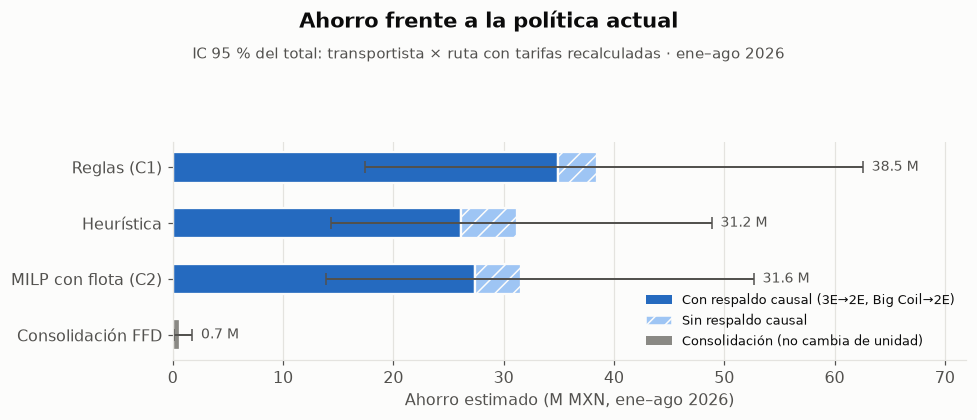

In [5]:
# FIG — Ahorro de cada enfoque frente a la política actual: parte con respaldo causal (sólida) y sin respaldo (rayada)
orden_fig = [e for e in ENFOQUES if e != 'Actual']
fig, ax = plt.subplots(figsize=(9, 3.9))
ax.set_axisbelow(True)                                             # la cuadrícula va detrás de las barras
for j, e in enumerate(orden_fig):
    r = res[e]
    if e in ASIGNACION:                                            # cambio de unidad: se separa por respaldo causal
        ax.barh(j, r['resp'], color=tc.SECUENCIAL[4], height=0.55, edgecolor=tc.SUPERFICIE, linewidth=1.5)
        ax.barh(j, r['sin_resp'], left=r['resp'], color=tc.SECUENCIAL[1], height=0.55, hatch='//', edgecolor=tc.SUPERFICIE, linewidth=1.5)
    else:                                                          # consolidación: otra palanca, sin clasificación causal
        ax.barh(j, r['ahorro'], color=tc.TINTA_3, height=0.55, edgecolor=tc.SUPERFICIE, linewidth=1.5)
    lo, hi = r['ahorro_ic']
    ax.errorbar(r['ahorro'], j, xerr=[[max(0, r['ahorro'] - lo)], [max(0, hi - r['ahorro'])]], fmt='none',
                ecolor=tc.TINTA_2, elinewidth=1.3, capsize=4)
    ax.text(hi + 0.8, j, f"{r['ahorro']:.1f} M", va='center', fontsize=9, color=tc.TINTA_2)
ax.set_yticks(range(len(orden_fig)), orden_fig); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set_xlim(0, max(res[e]['ahorro_ic'][1] for e in orden_fig) * 1.15)
ax.set_xlabel('Ahorro estimado (M MXN, ene–ago 2026)')
ax.legend(handles=[Patch(facecolor=tc.SECUENCIAL[4], label='Con respaldo causal (3E→2E, Big Coil→2E)'),
                   Patch(facecolor=tc.SECUENCIAL[1], hatch='//', edgecolor=tc.SUPERFICIE, label='Sin respaldo causal'),
                   Patch(facecolor=tc.TINTA_3, label='Consolidación (no cambia de unidad)')],
          loc='lower right', fontsize=8.5)
tc.titulo(fig, 'Ahorro frente a la política actual', 'IC 95 % del total: transportista × ruta con tarifas recalculadas · ene–ago 2026')
plt.show()

## 2. Discusión crítica

**Del número más alto al más defendible.** Los tres enfoques de asignación usan las mismas tarifas de referencia; sus diferencias vienen de los supuestos:

- **Reglas de C1 → MILP de C2.** C1 decide con el peso real (que se conoce hasta después de cargar) y sin límite de flota. Con el peso programado, que es lo que se sabe al pedir la unidad, el ahorro baja; con la disponibilidad semanal de flota, baja otra vez hasta los 31.6 M de C2. La cifra exacta de cada paso está en la celda siguiente.
- **Heurística.** Captura casi todo el ahorro del MILP con una regla que cualquiera puede aplicar, pero ignora la disponibilidad semanal: sus cambios no tienen garantía de flota.
- **Respaldo causal.** En todos los enfoques, la mayor parte del ahorro viene de 3 ejes → 2 ejes y Big Coil → 2 ejes, los dos movimientos cuyo efecto C2 sostiene. La parte sin respaldo (Torton → 2 ejes, 2 ejes → 3 ejes, Big Coil → 3 ejes, 3 ejes → Full) depende de diferencias de tarifa que C2 no pudo distinguir del ruido o de un efecto del transportista: es la primera que se debe descontar.

**Lo que ninguna comparación sobre ene–ago resuelve (C2):**

- **Disponibilidad.** La unidad pedida no siempre está disponible y no hay registro de cancelaciones. Con la flota semanal típica (P75) en lugar de la máxima, el MILP baja de 31.6 a 18.8 M (C2, sección 6.3). En el simulador, si 20 % de las solicitudes de la unidad sugerida no se surte, el ahorro de jul–ago pasa de 5.5 a 4.4 M; con 50 %, a 2.8 M (C2, sección 7.4).
- **Fuera de muestra.** Decidiendo solo con información de ene–jun, el right-sizing ahorra **5.5 M [3.2–8.7] en jul–ago** (C2, sección 7), unos 22 M al ritmo de ocho meses, por debajo de los 31.6 M de la comparación dentro de muestra.
- **Modelo de tarifas.** Con el Random Forest de tarifas (C2, sección 8), el ahorro verificable con costos reales casi no cambia (5.5 M en jul–ago) y el modelo agrega 1.0 M [0.7–1.3] en movimientos sin tarifa observada, que solo un piloto puede confirmar.

Ninguna asignación verifica dimensiones, producto, horario o requisitos del cliente, y las tarifas históricas no son ofertas.

**Consolidación.** Explora otra palanca y conserva cada carga indivisible. No reoptimiza flota ni comprueba ventanas de entrega, secuencia de carga o negociación de tarifa. En una operación donde las cargas individuales rondan 26–30 t, dos cargas típicas no caben en 36.575 t: la capacidad vacía agregada no implica que se puedan juntar pedidos. No es un problema de paquetería. Esta conclusión debe contrastarse con la composición real de pedidos dentro de cada viaje.

In [6]:
# Propósito: Cifras de la discusión: de las reglas de C1 al MILP de C2 paso a paso, cuánto captura la heurística,
# qué parte del ahorro tiene respaldo causal y por qué casi no se puede consolidar.
pasos = [('Reglas de C1 (peso real, sin flota)', k_c1),
         ('Peso programado, sin flota (MILP de C2 sin restricción de flota)', k_libre),
         ('Peso programado y disponibilidad de flota (MILP de C2)', k_m)]
print('De C1 a C2:')
for nombre, k in pasos:
    print(f'  {ahorro(k).sum()/1e6:5.1f} M MXN · {(k != k0).sum():5,} viajes · {nombre}')
ratio = ahorro(k_h).sum() / ahorro(k_m).sum()
print(f'La heurística captura {ratio:.1%} del ahorro del MILP; puede superar 100 % porque no respeta su límite de flota.')
for e in ASIGNACION:
    print(f"Con respaldo causal en {e}: {res[e]['resp'] / res[e]['ahorro']:.0%} del ahorro.")
print(f'Peso real medio / mediano: {np.mean(qr):.1f} / {np.median(qr):.1f} t; límite FFD: 36.575 t.')
print(f'En FFD: {interv_c.sum():,} viajes involucrados, {(~activo).sum():,} eliminados; ahorro estimado {ah_c.sum()/1e6:.2f} M MXN.')

De C1 a C2:
   38.5 M MXN · 5,784 viajes · Reglas de C1 (peso real, sin flota)
   34.9 M MXN · 5,377 viajes · Peso programado, sin flota (MILP de C2 sin restricción de flota)
   31.6 M MXN · 4,721 viajes · Peso programado y disponibilidad de flota (MILP de C2)
La heurística captura 98.8% del ahorro del MILP; puede superar 100 % porque no respeta su límite de flota.
Con respaldo causal en Reglas (C1): 91% del ahorro.
Con respaldo causal en Heurística: 84% del ahorro.
Con respaldo causal en MILP con flota (C2): 87% del ahorro.
Peso real medio / mediano: 28.7 / 29.5 t; límite FFD: 36.575 t.
En FFD: 74 viajes involucrados, 37 eliminados; ahorro estimado 0.70 M MXN.


## 3. Diagnóstico de casos raros: 20 observaciones que contradicen el patrón

Son señales para investigación, no errores ni evidencia de causalidad. Cinco familias, cuatro casos cada una:

- **Sobrecosto y subcosto extremos:** costo frente a la mediana de ruta × unidad × transportista (≥ 5 registros); se escogen los extremos por razón.
- **Peso y equipo:** mayores cargas de 2 ejes frente al techo operativo P99.
- **Inversión tarifaria:** rutas con ≥ 5 viajes de cada unidad donde la mediana de 2 ejes supera a la de 3 ejes; un viaje de 2 ejes por ruta. Es el 9 % de rutas donde, según C2 (sección 4.3), el 2 ejes no es más barato.
- **Posible sustitución por indisponibilidad** (nueva, de C2 sección 1.4): viajes en 3 ejes con ≤ 26 t programadas en rutas donde lo normal es el 2 ejes (≥ 60 % de sus viajes de 2 y 3 ejes, ≥ 20 viajes). Pueden ser solicitudes de 2 ejes que no se surtieron. Se escogen los más caros frente a la mediana de 3 ejes de su ruta.

Se evitan IDs repetidos; el orden es determinista. No se eliminan atípicos del universo.

In [7]:
# Propósito: Seleccionar 20 casos raros (4 por cada una de 5 familias) que contradicen el patrón, para investigarlos con Ternium.
POR_FAMILIA = 4
d = df.copy(); d['unidad'] = d.Unidad.astype(str)
keys = ['Ruta_ID', 'unidad', 'Transportista']
# Costo de referencia: mediana de ruta × unidad × transportista (se exigen ≥ 5 viajes)
grp = d.groupby(keys, observed=True).Costo
med = grp.transform('median'); count = grp.transform('size')
d['ref'] = med; d['ratio'] = d.Costo / med.where(med > 0)
valid = (count >= 5) & (med > 0) & (d.Costo > 0)
selecciones = []; usados = set()
def tomar(candidatos, familia, diag, evidencia, ref_col='ref'):
    # Agrega los primeros candidatos no usados, con su familia, diagnóstico y evidencia a pedir
    candidatos = candidatos[~candidatos.ID_VIAJE.isin(usados)].drop_duplicates('ID_VIAJE').head(POR_FAMILIA).copy()
    usados.update(candidatos.ID_VIAJE)
    candidatos['Familia'] = familia; candidatos['Diagnóstico provisional'] = diag; candidatos['Evidencia requerida'] = evidencia
    candidatos['Costo esperado / mediana'] = candidatos[ref_col]
    selecciones.append(candidatos)
tomar(d[valid].sort_values('ratio', ascending=False), 'Sobrecosto extremo', 'Posible urgencia, spot o cargo extraordinario', 'Orden, contrato, desglose del flete y urgencia')
tomar(d[valid].sort_values('ratio'), 'Subcosto extremo', 'Posible retorno, crédito o ajuste', 'Factura, nota de crédito, contrato y viaje de retorno')
p99 = tc.capacidades(df).loc['2 Ejes', 'Techo_P99_t']
tomar(d[d.unidad.eq('2 Ejes')].sort_values('Toneladas_Reales', ascending=False), 'Peso y equipo', f'Peso elevado frente a P99 de 2 ejes ({p99:.1f} t); verificar equipo', 'Báscula, tara, configuración, permiso y unidad declarada')
# Inversión tarifaria: rutas donde la mediana de 2 ejes supera a la de 3 ejes
tar = d.groupby(['Ruta_ID', 'unidad'], observed=True).Costo.agg(['median', 'size']).reset_index()
a = tar[(tar.unidad == '2 Ejes') & (tar['size'] >= 5)].merge(tar[(tar.unidad == '3 Ejes') & (tar['size'] >= 5)], on='Ruta_ID', suffixes=('_2', '_3'))
a = a[a.median_2 > a.median_3].sort_values('Ruta_ID')
inv = d[d.unidad.eq('2 Ejes')].merge(a[['Ruta_ID', 'median_3', 'median_2']], on='Ruta_ID')
inv = inv[inv.Costo > inv.median_3].sort_values(['Ruta_ID', 'ID_VIAJE']).drop_duplicates('Ruta_ID')
tomar(inv, 'Inversión tarifaria', 'Mediana de 2 ejes mayor que la de 3 ejes en la misma ruta', 'Contratos, fechas, transportistas, servicio y comparabilidad', 'median_3')
# Posible sustitución (definición de C2, sección 1.4): 3 ejes con ≤ 26 t programadas en rutas donde lo normal es el 2 ejes
x = d[d.unidad.isin(['2 Ejes', '3 Ejes']) & (d.Programado_t > 0.5) & ~d.Flag_Discrepancia_Peso.astype(bool)]
part_2e = x.groupby('Ruta_ID').unidad.apply(lambda s: (s == '2 Ejes').mean()); n_ruta = x.groupby('Ruta_ID').size()
rutas_2e = part_2e[(part_2e >= 0.6) & (n_ruta >= 20)].index
med_3e = x[x.unidad.eq('3 Ejes')].groupby('Ruta_ID').Costo.median().rename('med_3e')
sust = x[x.Ruta_ID.isin(rutas_2e) & x.unidad.eq('3 Ejes') & (x.Programado_t <= 26)].join(med_3e, on='Ruta_ID')
sust = sust.assign(r3=sust.Costo / sust.med_3e).sort_values(['r3', 'ID_VIAJE'], ascending=[False, True])
tomar(sust, 'Posible sustitución', 'Carga de 2 ejes en 3 ejes en ruta de 2 ejes: posible solicitud no surtida', 'Solicitud original, cancelaciones y disponibilidad de 2 ejes esa semana', 'med_3e')
casos = pd.concat(selecciones, ignore_index=True)
assert len(casos) == 20 and casos.ID_VIAJE.nunique() == 20
casos = casos.drop(columns=['Unidad']).rename(columns={'PLANTA_ORIGEN': 'Planta', 'Ciudad Destino': 'Destino', 'unidad': 'Unidad', 'Toneladas_Reales': 'Peso (t)', 'Costo': 'Costo real (MXN)'})
cols = ['Familia', 'ID_VIAJE', 'Planta', 'Destino', 'Unidad', 'Peso (t)', 'Costo real (MXN)', 'Costo esperado / mediana', 'Diagnóstico provisional', 'Evidencia requerida']
display(casos[cols].round({'Peso (t)': 1, 'Costo esperado / mediana': 0}))
print(f'Posibles sustituciones en el universo: {len(sust):,} viajes en {len(rutas_2e)} rutas de 2 ejes. '
      'En peso y equipo, la referencia es la mediana ruta × unidad × transportista; puede no existir si falta el grupo.')

,Familia,ID_VIAJE,Planta,Destino,Unidad,Peso (t),Costo real (MXN),Costo esperado / mediana,Diagnóstico provisional,Evidencia requerida
0,Sobrecosto extremo,73976411,CEDI Tuxtla,San Fernando,Torton,14.8,19600,3030.0,"Posible urgencia, spot o cargo extraordinario","Orden, contrato, desglose del flete y urgencia"
1,Sobrecosto extremo,73822939,CEDI Puebla,Amozoc,Torton,11.7,36180,5800.0,"Posible urgencia, spot o cargo extraordinario","Orden, contrato, desglose del flete y urgencia"
2,Sobrecosto extremo,73831414,CEDI Tuxtla,San Fernando,Torton,16.0,16377,3030.0,"Posible urgencia, spot o cargo extraordinario","Orden, contrato, desglose del flete y urgencia"
3,Sobrecosto extremo,74881177,Juventud,Gómez Palacios,3 Ejes,30.7,78715,19374.0,"Posible urgencia, spot o cargo extraordinario","Orden, contrato, desglose del flete y urgencia"
4,Subcosto extremo,74037608,CEDI Tuxtla,San Fernando,Torton,6.9,3000,18000.0,"Posible retorno, crédito o ajuste","Factura, nota de crédito, contrato y viaje de ..."
5,Subcosto extremo,73942680,CEDI Tuxtla,San Fernando,Torton,9.7,3000,18000.0,"Posible retorno, crédito o ajuste","Factura, nota de crédito, contrato y viaje de ..."
6,Subcosto extremo,73843846,CEDI Tuxtla,Chiapa de Corzo,Torton,7.1,3358,17250.0,"Posible retorno, crédito o ajuste","Factura, nota de crédito, contrato y viaje de ..."
7,Subcosto extremo,74321209,CEDI Tuxtla,Chiapa de Corzo,Torton,8.2,3500,17250.0,"Posible retorno, crédito o ajuste","Factura, nota de crédito, contrato y viaje de ..."
8,Peso y equipo,73900669,Pesquería,San Luis Potosí,2 Ejes,34.4,24890,26134.0,Peso elevado frente a P99 de 2 ejes (29.0 t); ...,"Báscula, tara, configuración, permiso y unidad..."
9,Peso y equipo,74714305,CEDI Puebla,Santiago Mihuatlán,2 Ejes,31.9,7373,6763.0,Peso elevado frente a P99 de 2 ejes (29.0 t); ...,"Báscula, tara, configuración, permiso y unidad..."


Posibles sustituciones en el universo: 159 viajes en 82 rutas de 2 ejes. En peso y equipo, la referencia es la mediana ruta × unidad × transportista; puede no existir si falta el grupo.
